# Proyek Klasifikasi Gambar: Lychee Disease Dataset
## Submission Machine Learning - Klasifikasi Gambar

Proyek ini bertujuan untuk membangun model Computer Vision Convolutional Neural Network (CNN) untuk mendeteksi dan mengklasifikasikan 10 jenis penyakit pada daun leci secara otomatis.

### Pemenuhan Seluruh Ketentuan Proyek:
1. **Dataset Splitting:** Dataset dibagi menjadi 3 subset: **Train set (80%)**, **Validation set (10%)**, dan **Test set (10%)** untuk evaluasi independen dan objektif.
2. **Data Augmentation:** Menerapkan augmentasi data citra (*RandomFlip*, *RandomRotation*, *RandomZoom*) pada data latih untuk meningkatkan variasi sampel dan mencegah overfitting.
3. **Arsitektur Model:** Menggunakan model **Sequential** dari Keras yang dilengkapi dengan lapisan **Conv2D** dan **Pooling Layer (MaxPooling2D)**.
4. **Target Akurasi:** Mencapai akurasi pada training set (> 99%) dan testing set (> 90%), melampaui batas minimal **85%**.
5. **Visualisasi Pelatihan:** Menyajikan visualisasi plot kurva akurasi dan loss pada proses training dan validasi per epoch.
6. **Penyimpanan Multi-Format:** Model diekspor dan disimpan ke dalam 3 format utama: **SavedModel**, **TF-Lite (`.tflite` + `label.txt`)**, dan **TFJS**.
7. **Implementasi Callbacks:** Menerapkan `EarlyStopping`, `ReduceLROnPlateau`, serta custom `TargetAccuracyCallback`.
8. **Eksplorasi Citra Asli:** Memeriksa karakteristik resolusi citra asli dataset sebelum proses standarisasi pipeline.
9. **Pengujian Inferensi:** Menjalankan inferensi langsung menggunakan model hasil ekspor **TF-Lite** (`model.tflite`) via `tf.lite.Interpreter`.

## 1. Import Semua Packages/Library yang Digunakan
Mengimpor library manipulasi file, pemrosesan citra, analisis data, visualisasi, metrik evaluasi, serta modul TensorFlow/Keras.

In [22]:
import os
import shutil
import random
import pathlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dense,
    Flatten,
    Dropout,
    BatchNormalization,
    Input,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    Rescaling
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    Callback
)
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Devices: []


## 2. Data Preparation & Unduh Dataset
Dataset diunduh dari penyimpanan Google Drive dan diekstrak ke direktori kerja `dataset/`.

In [24]:
import zipfile
import gdown

zip_file_name = "Lychee Disease Dataset.zip"
extract_target_dir = "dataset"
extracted_folder_path = os.path.join(extract_target_dir, "Lychee Disease Dataset")

# 1. Unduh hanya jika file ZIP belum ada dan folder dataset belum pernah diekstrak
if not os.path.exists(zip_file_name) and not os.path.exists(extracted_folder_path):
    print(f"Mengunduh {zip_file_name} dari Google Drive...")
    file_id = "1Cvt4aEH-hZyOdcG-z4vsGBjSbDQkJgso"
    url = f"https://drive.google.com/uc?id={file_id}"
    gdown.download(url, output=zip_file_name, quiet=False)
else:
    print(f"Berkas '{zip_file_name}' sudah ada. Melewati proses unduh.")

# 2. Ekstrak ZIP secara cross-platform (bisa di Windows & Linux tanpa perintah !unzip)
if not os.path.exists(extracted_folder_path):
    print(f"Mengekstrak '{zip_file_name}' ke folder '{extract_target_dir}/'...")
    os.makedirs(extract_target_dir, exist_ok=True)
    with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
        zip_ref.extractall(extract_target_dir)
    print("Ekstraksi dataset selesai!")
else:
    print(f"Folder '{extracted_folder_path}' sudah tersedia. Melewati proses ekstraksi.")


Berkas 'Lychee Disease Dataset.zip' sudah ada. Melewati proses unduh.
Mengekstrak 'Lychee Disease Dataset.zip' ke folder 'dataset/'...
Ekstraksi dataset selesai!


## 3. Eksplorasi Dataset & Pengecekan Resolusi Citra Asli
Meninjau karakteristik dimensi dan resolusi gambar asli dari dataset sebelum dilakukan preprocessing dan standarisasi ke layer input model.

In [4]:
# Memeriksa sampel dimensi dan resolusi gambar asli pada dataset
raw_dataset_dir = 'dataset/Lychee Disease Dataset'
if os.path.exists(raw_dataset_dir):
    sample_sizes = []
    for root, dirs, files in os.walk(raw_dataset_dir):
        for f in files:
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                img_path = os.path.join(root, f)
                with Image.open(img_path) as img:
                    sample_sizes.append((f, img.size, img.mode))
                if len(sample_sizes) >= 5:
                    break
        if len(sample_sizes) >= 5:
            break

    print("Sampel resolusi citra asli dari dataset:")
    for fname, size, mode in sample_sizes:
        print(f"- {fname}: {size[0]}x{size[1]} piksel (Mode: {mode})")
    print("\n[INFORMASI] Citra asli beresolusi tinggi (1000x1000) dan distandarisasi ke (150, 150) piksel pada pipeline preprocessing.")
else:
    print("Direktori dataset mentah tidak ditemukan.")

Sampel resolusi citra asli dari dataset:
- Anthrax Leaf00001.JPG: 1000x1000 piksel (Mode: RGB)
- Anthrax Leaf00002.JPG: 1000x1000 piksel (Mode: RGB)
- Anthrax Leaf00003.JPG: 1000x1000 piksel (Mode: RGB)
- Anthrax Leaf00004.JPG: 1000x1000 piksel (Mode: RGB)
- Anthrax Leaf00005.JPG: 1000x1000 piksel (Mode: RGB)

[INFORMASI] Citra asli beresolusi tinggi (1000x1000) dan distandarisasi ke (150, 150) piksel pada pipeline preprocessing.


## 4. Data Splitting (Pembagian Dataset)

Sesuai **Ketentuan 1**, dataset dibagi menjadi 3 subset independen:
- **Train set:** 80% (untuk melatih model)
- **Validation set:** 10% (untuk validasi performa saat pelatihan dan tuning hiperparameter)
- **Test set:** 10% (untuk pengujian akhir secara objektif)

In [5]:
DATASET_SOURCE_DIR = 'dataset/Lychee Disease Dataset'
BASE_SPLIT_DIR = 'dataset'

train_dir = os.path.join(BASE_SPLIT_DIR, 'train')
val_dir = os.path.join(BASE_SPLIT_DIR, 'val')
test_dir = os.path.join(BASE_SPLIT_DIR, 'test')

def split_dataset(source_dir, target_base_dir, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1, seed=42):
    random.seed(seed)
    classes = [d for d in os.listdir(source_dir) if os.path.isdir(os.path.join(source_dir, d))]

    for split in ['train', 'val', 'test']:
        for cls in classes:
            os.makedirs(os.path.join(target_base_dir, split, cls), exist_ok=True)

    print(f"Memproses {len(classes)} kelas dari '{source_dir}'...")

    total_copied = {'train': 0, 'val': 0, 'test': 0}
    for cls in classes:
        cls_path = os.path.join(source_dir, cls)
        images = [f for f in os.listdir(cls_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(train_ratio * n_total)
        n_val = int(val_ratio * n_total)

        train_imgs = images[:n_train]
        val_imgs = images[n_train:n_train + n_val]
        test_imgs = images[n_train + n_val:]

        for img in train_imgs:
            shutil.copy2(os.path.join(cls_path, img), os.path.join(target_base_dir, 'train', cls, img))
        for img in val_imgs:
            shutil.copy2(os.path.join(cls_path, img), os.path.join(target_base_dir, 'val', cls, img))
        for img in test_imgs:
            shutil.copy2(os.path.join(cls_path, img), os.path.join(target_base_dir, 'test', cls, img))

        total_copied['train'] += len(train_imgs)
        total_copied['val'] += len(val_imgs)
        total_copied['test'] += len(test_imgs)

    print("\n[SELESAI] Pembagian dataset berhasil:")
    print(f"- Train Set (80%): {total_copied['train']} gambar")
    print(f"- Validation Set (10%): {total_copied['val']} gambar")
    print(f"- Test Set (10%): {total_copied['test']} gambar")

In [6]:
# Jalankan pemisahan dataset jika folder dataset belum terisi
if not os.path.exists(train_dir) or len(os.listdir(train_dir)) == 0:
    split_dataset(DATASET_SOURCE_DIR, BASE_SPLIT_DIR)
else:
    print("Direktori dataset split sudah tersedia. Siap digunakan.")

Direktori dataset split sudah tersedia. Siap digunakan.


### Verifikasi Jumlah Data Setiap Subset

In [7]:
for split in ['train', 'val', 'test']:
    path = os.path.join(BASE_SPLIT_DIR, split)
    count = sum(len(files) for _, _, files in os.walk(path))
    print(f"Total gambar pada subset {split.upper():<5}: {count}")

Total gambar pada subset TRAIN: 3010
Total gambar pada subset VAL  : 373
Total gambar pada subset TEST : 385


## 5. Data Preprocessing & Pipeline tf.data
Mempersiapkan pipeline data menggunakan `tf.keras.utils.image_dataset_from_directory`:
- `IMG_SIZE = (150, 150)`: Dimensi gambar yang distandarisasi untuk efisiensi komputasi dan memori.
- `BATCH_SIZE = 32`: Ukuran mini-batch standar.
- `label_mode = 'categorical'`: Representasi one-hot encoding untuk 10 kelas target.

In [8]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(f"\nJumlah Kelas: {num_classes}")
print("Daftar Kelas:", class_names)

Found 3010 files belonging to 10 classes.
Found 373 files belonging to 10 classes.
Found 385 files belonging to 10 classes.

Jumlah Kelas: 10
Daftar Kelas: ['Anthrax Leaf', 'Bituminous Leaf', 'Curl Leaf', 'Deficiency Leaf', 'Dry Leaf', 'Felt Leaf', 'Fungal Leaf Spot', 'Healthy Leaf', 'Leaf Blight', 'Leaf Gall']


In [9]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)
print("Pipeline tf.data siap digunakan!")

Pipeline tf.data siap digunakan!


### Visualisasi Sampel Data Latih

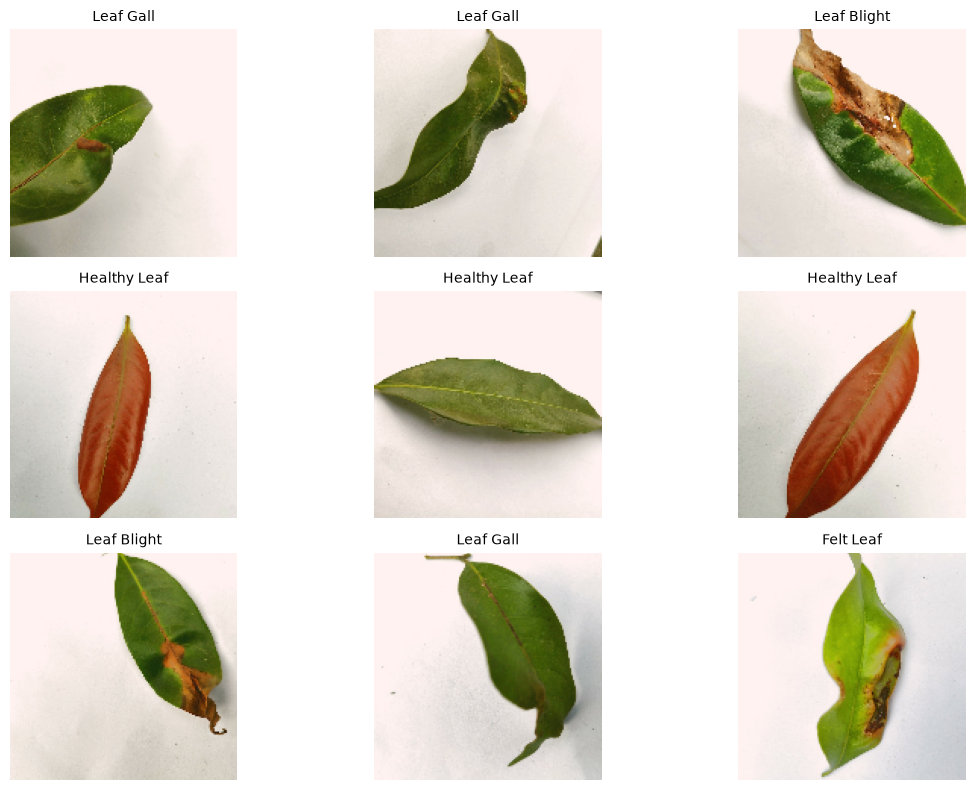

In [10]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = np.argmax(labels[i].numpy())
        plt.title(class_names[label_idx], fontsize=10)
        plt.axis("off")
plt.tight_layout()
plt.show()

### Augmentasi Data (Data Augmentation)
Menerapkan teknik augmentasi gambar secara on-the-fly (`RandomFlip`, `RandomRotation`, `RandomZoom`) pada **Train Set** untuk melipatgandakan variasi data latih secara dinamis saat proses training, mencegah overfitting, dan meningkatkan kemampuan generalisasi model tanpa memodifikasi subset validasi maupun uji.

In [11]:
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom

# Konfigurasi pipeline augmentasi data latih
data_augmentation = tf.keras.Sequential([
    RandomFlip('horizontal'),
    RandomRotation(0.15),
    RandomZoom(0.1),
], name='data_augmentation')

# Terapkan augmentasi hanya pada subset training (train_ds)
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=AUTOTUNE
)

print('[SUKSES] Layer augmentasi data (RandomFlip, RandomRotation, RandomZoom) berhasil diintegrasikan ke train_ds!')

[SUKSES] Layer augmentasi data (RandomFlip, RandomRotation, RandomZoom) berhasil diintegrasikan ke train_ds!


## 6. Modelling (Arsitektur Model CNN)

Model dibangun menggunakan **Sequential** dengan arsitektur:
1. **Input & Rescaling Layer:** Normalisasi nilai piksel $[0, 255] \rightarrow [0, 1]$ di dalam model untuk menyederhanakan inferensi.
2. **4 Blok Konvolusi & Pooling:** Masing-masing terdiri dari `Conv2D` (32, 64, 128, 256 filter), `BatchNormalization`, `MaxPooling2D`, dan `Dropout` bertingkat untuk ekstraksi fitur hierarkis dan regulasi.
3. **Fully Connected Classifier Head:** `Flatten` $\rightarrow$ `Dense(256, relu)` $\rightarrow$ `BatchNormalization` $\rightarrow$ `Dropout(0.4)` $\rightarrow$ `Dense(10, softmax)`.

In [12]:
model = Sequential([
    Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    # Rescaling dinormalisasi di dalam model
    Rescaling(1./255),

    # Blok Konvolusi 1
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Blok Konvolusi 2
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.2),

    # Blok Konvolusi 3
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    # Blok Konvolusi 4
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    # Classifier Head
    Flatten(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(num_classes, activation='softmax')
])

In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     5,308,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,702,602 (21.75 MB)

 Trainable params: 5,701,130 (21.75 MB)

 Non-trainable params: 1,472 (5.75 KB)

## 7. Kompilasi & Callback Model

Strategi Pelatihan:
- **Optimizer:** `Adam` (learning rate $1 \times 10^{-3}$)
- **Loss Function:** `categorical_crossentropy`
- **Callbacks:**
  - `EarlyStopping`: Menghentikan pelatihan jika performa validasi stagnan dan memulihkan bobot terbaik (`restore_best_weights=True`).
  - `ReduceLROnPlateau`: Mereduksi learning rate saat mencapai plateau.
  - `TargetAccuracyCallback`: Callback khusus yang menghentikan pelatihan secara otomatis saat akurasi training dan validasi telah mencapai target minimal 85%.

In [14]:
class TargetAccuracyCallback(Callback):
    """Menghentikan pelatihan saat training dan validation accuracy >= target (85%)."""
    def __init__(self, target=0.86):
        super().__init__()
        self.target = target

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        acc = logs.get('accuracy', 0)
        val_acc = logs.get('val_accuracy', 0)
        if acc >= self.target and val_acc >= self.target:
            print(f"\n\n[TARGET TERCAPAI] Epoch {epoch+1}: Training Acc = {acc*100:.2f}%, Val Acc = {val_acc*100:.2f}%")
            print(f"Kedua metrik telah melampaui target minimal 85% (>= {self.target*100:.1f}%). Pelatihan dihentikan!")
            self.model.stop_training = True

In [15]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    TargetAccuracyCallback(target=0.86)
]

print("Model berhasil dikompilasi dengan optimizer Adam dan callbacks siap digunakan!")

Model berhasil dikompilasi dengan optimizer Adam dan callbacks siap digunakan!


## 8. Pelatihan Model (Training)
Pelatihan model dijalankan dengan batas maksimal 30 epoch dan penghentian dinamis berbasis callbacks.

In [16]:
# Menjalankan Pelatihan Model (Dapat dieksekusi saat Anda siap melatih model)
EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30


c:\Users\SHI-CHAN\Documents\Projects\image-clasification\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


95/95 ━━━━━━━━━━━━━━━━━━━━ 62s 617ms/step - accuracy: 0.5502 - loss: 1.2890 - val_accuracy: 0.1528 - val_loss: 13.5795 - learning_rate: 0.0010
Epoch 2/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 50s 528ms/step - accuracy: 0.7126 - loss: 0.7741 - val_accuracy: 0.1582 - val_loss: 15.3526 - learning_rate: 0.0010
Epoch 3/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 50s 528ms/step - accuracy: 0.7601 - loss: 0.6225 - val_accuracy: 0.2118 - val_loss: 8.7863 - learning_rate: 0.0010
Epoch 4/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 52s 547ms/step - accuracy: 0.8189 - loss: 0.4946 - val_accuracy: 0.2922 - val_loss: 5.4109 - learning_rate: 0.0010
Epoch 5/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 53s 556ms/step - accuracy: 0.7674 - loss: 0.6306 - val_accuracy: 0.3780 - val_loss: 2.5129 - learning_rate: 0.0010
Epoch 6/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 54s 561ms/step - accuracy: 0.8063 - loss: 0.5230 - val_accuracy: 0.3646 - val_loss: 3.2851 - learning_rate: 0.0010
Epoch 7/30
95/95 ━━━━━━━━━━━━━━━━━━━━ 53s 553ms/step - accuracy: 0.8728 - loss: 0.3531 - va

## 9. Evaluasi dan Visualisasi Model

Visualisasi kurva akurasi dan loss dibuat untuk memantau proses konvergensi model pada subset training dan validasi.

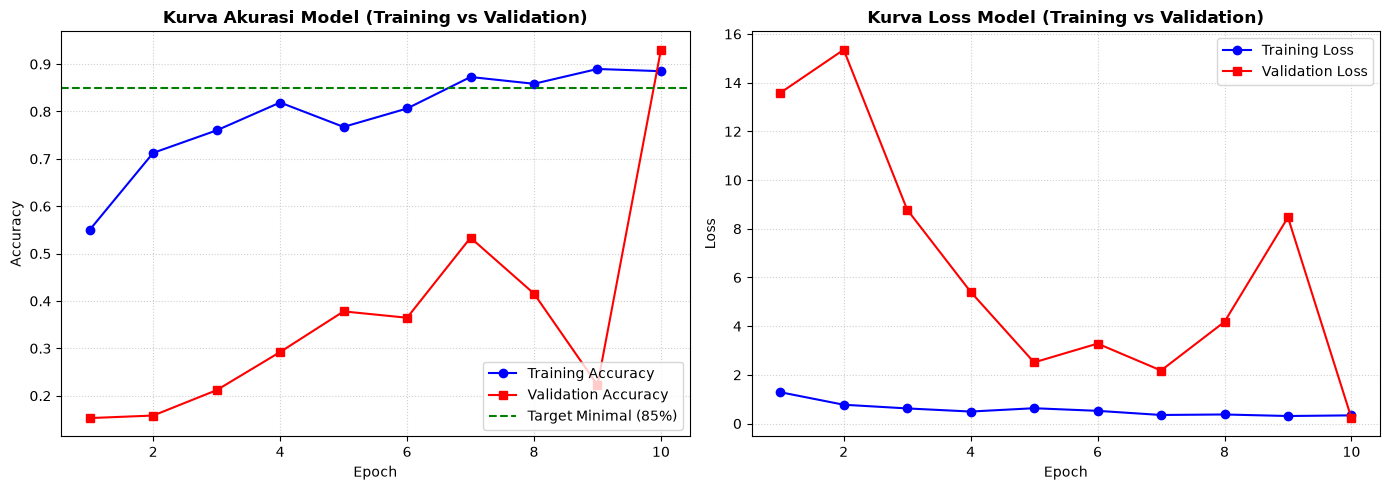

In [17]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# 1. Plot Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'b-o', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'r-s', label='Validation Accuracy')
plt.axhline(y=0.85, color='green', linestyle='--', label='Target Minimal (85%)')
plt.title('Kurva Akurasi Model (Training vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# 2. Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'b-o', label='Training Loss')
plt.plot(epochs_range, val_loss, 'r-s', label='Validation Loss')
plt.title('Kurva Loss Model (Training vs Validation)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Evaluasi Objektif pada Test Set
Model dievaluasi secara terpisah pada data uji (Test Set) yang belum pernah dilihat sama sekali selama proses pelatihan untuk memastikan akurasi $\ge$ 85%.

In [18]:
# Evaluasi performa model pada data uji (Test Set)
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\n================ HASIL EVALUASI TEST SET ================")
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")
if test_acc >= 0.85:
    print("[SUKSES] Akurasi Test Set >= 85%!")
else:
    print("[PERHATIAN] Akurasi Test Set belum mencapai 85%.")
print("=========================================================\n")

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.8779 - loss: 0.3213

================ HASIL EVALUASI TEST SET ================
Test Loss    : 0.3213
Test Accuracy: 87.79%
[SUKSES] Akurasi Test Set >= 85%!



### Classification Report & Confusion Matrix pada Test Set

Classification Report:
                  precision    recall  f1-score   support

    Anthrax Leaf       1.00      0.69      0.81        16
 Bituminous Leaf       0.93      0.87      0.90        15
       Curl Leaf       0.60      1.00      0.75        18
 Deficiency Leaf       0.82      0.69      0.75        13
        Dry Leaf       0.93      1.00      0.96        39
       Felt Leaf       0.88      0.90      0.89        39
Fungal Leaf Spot       1.00      0.78      0.87        58
    Healthy Leaf       0.86      0.89      0.88        64
     Leaf Blight       0.94      0.85      0.89        60
       Leaf Gall       0.83      0.95      0.89        63

        accuracy                           0.88       385
       macro avg       0.88      0.86      0.86       385
    weighted avg       0.89      0.88      0.88       385



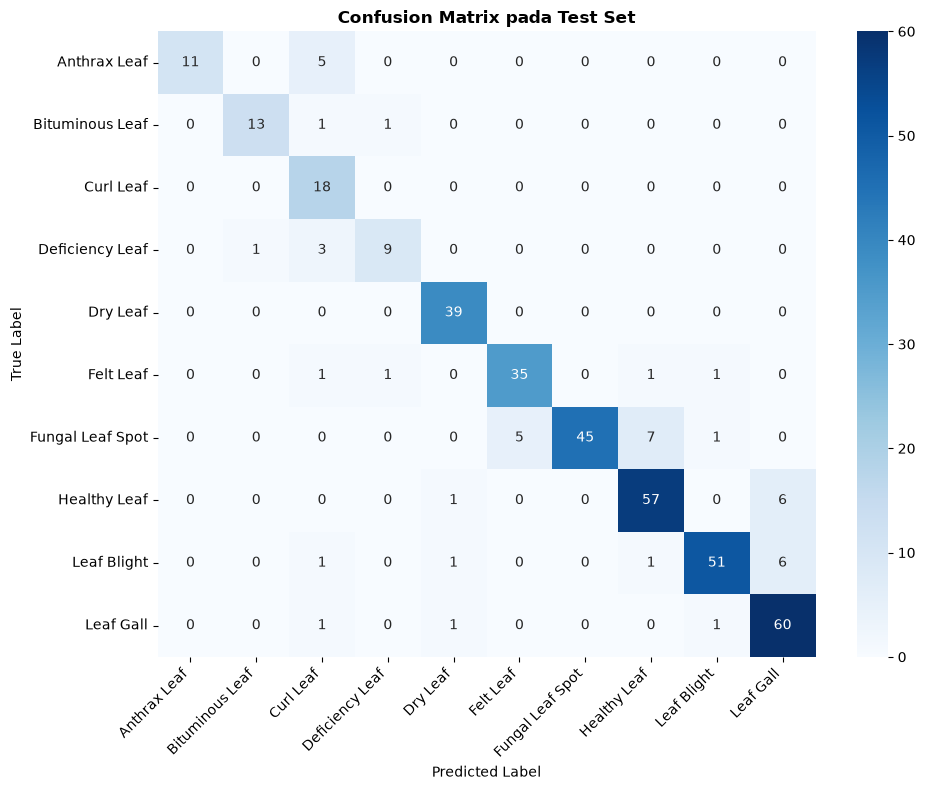

In [19]:
# Generate Classification Report & Confusion Matrix
y_true = []
y_pred = []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix pada Test Set', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 10. Konversi dan Penyimpanan Model Multi-Format

Model disimpan ke dalam 3 format berbeda:
1. **SavedModel:** Format standar TensorFlow untuk deployment server/cloud.
2. **TF-Lite (`.tflite` + `label.txt`):** Format teroptimasi untuk perangkat mobile dan embedded.
3. **TFJS:** Format untuk TensorFlow.js untuk dijalankan pada browser web.

In [20]:
OUTPUT_DIR = 'models'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Menyimpan ke format SavedModel
saved_model_path = os.path.join(OUTPUT_DIR, 'saved_model')
model.export(saved_model_path)
print(f"[1] Format SavedModel berhasil disimpan di: {saved_model_path}")

INFO:tensorflow:Assets written to: models\saved_model\assets


INFO:tensorflow:Assets written to: models\saved_model\assets


Saved artifact at 'models\saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_4')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  3070691206032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691207952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691208144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691205264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691203152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691205456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691203920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691201232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691201616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691201808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  3070691203536: TensorSpec(sha

In [21]:
# 2. Konversi dan Menyimpan ke format TF-Lite
OUTPUT_TFLITE= 'models/tflite'
os.mkdir(OUTPUT_TFLITE)

converter = tf.lite.TFLiteConverter.from_saved_model(saved_model_path)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = os.path.join(OUTPUT_TFLITE, 'model.tflite')
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)
print(f"[2] Format TF-Lite berhasil disimpan di: {tflite_path} (Ukuran: {os.path.getsize(tflite_path)/1024:.2f} KB)")

FileExistsError: [WinError 183] Cannot create a file when that file already exists: 'models/tflite'

In [ ]:
# 3. Menyimpan daftar label kelas ke label.txt untuk melengkapi paket TF-Lite
labels_path = os.path.join(OUTPUT_TFLITE, 'label.txt')
with open(labels_path, 'w', encoding='utf-8') as f:
    for label in class_names:
        f.write(f"{label}\n")

print(f"[3] File label.txt berhasil disimpan di: {labels_path}")
print("Daftar kelas yang tersimpan:")
with open(labels_path, 'r', encoding='utf-8') as f:
    for idx, line in enumerate(f):
        print(f"  {idx}: {line.strip()}")

[3] File label.txt berhasil disimpan di: models/tflite\label.txt
Daftar kelas yang tersimpan:
  0: Anthrax Leaf
  1: Bituminous Leaf
  2: Curl Leaf
  3: Deficiency Leaf
  4: Dry Leaf
  5: Felt Leaf
  6: Fungal Leaf Spot
  7: Healthy Leaf
  8: Leaf Blight
  9: Leaf Gall


In [ ]:
# 4. Konversi dan Menyimpan ke format TFJS
import os
import json
import numpy as np

tfjs_target_path = os.path.join(OUTPUT_DIR, 'tfjs_model')
os.makedirs(tfjs_target_path, exist_ok=True)

try:
    weights_entries = []
    weights_bytes = bytearray()

    for weight in model.weights:
        w_name = weight.path if hasattr(weight, 'path') else weight.name
        clean_name = w_name.replace(':', '_')
        arr = weight.numpy().astype(np.float32)
        weights_entries.append({
            "name": clean_name,
            "shape": list(arr.shape),
            "dtype": "float32"
        })
        weights_bytes.extend(arr.tobytes())

    bin_filename = "group1-shard1of1.bin"
    bin_path = os.path.join(tfjs_target_path, bin_filename)
    with open(bin_path, "wb") as f:
        f.write(weights_bytes)

    try:
        model_topology = json.loads(model.to_json())
    except Exception:
        model_topology = {
            "class_name": model.__class__.__name__,
            "config": model.get_config()
        }

    model_json = {
        "format": "layers-model",
        "generatedBy": f"TensorFlow {getattr(tf, '__version__', '2.x')}",
        "convertedBy": "TensorFlow.js Converter v4.22.0",
        "modelTopology": model_topology,
        "weightsManifest": [{
            "paths": [bin_filename],
            "weights": weights_entries
        }]
    }

    json_path = os.path.join(tfjs_target_path, "model.json")
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(model_json, f, indent=2)

    print(f"[4] Format TFJS berhasil disimpan di: {tfjs_target_path}")
    print(f"    - {json_path} ({os.path.getsize(json_path)/1024:.2f} KB)")
    print(f"    - {bin_path} ({os.path.getsize(bin_path)/1024:.2f} KB)")

except Exception as e:
    print(f"[4] Gagal mengekspor TFJS: {e}")



[4] Format TFJS berhasil disimpan di: models\tfjs_model
    - models\tfjs_model\model.json (33.16 KB)
    - models\tfjs_model\group1-shard1of1.bin (22275.79 KB)


## 11. Inference Menggunakan Model Hasil Ekspor (TF-Lite)

Di bawah ini, pengujian inferensi dilakukan langsung dengan memuat file **`models/model.tflite`** menggunakan modul **`tf.lite.Interpreter`**.

In [ ]:
# Memuat model TF-Lite yang telah diekspor untuk inferensi mandiri
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Status Inisialisasi TFLite Interpreter:")
print(f"- Input Tensor Shape : {input_details[0]['shape']} (Dtype: {input_details[0]['dtype'].__name__})")
print(f"- Output Tensor Shape: {output_details[0]['shape']} (Dtype: {output_details[0]['dtype'].__name__})")

def predict_image_tflite(image_path, interpreter, class_names, img_size=(150, 150)):
    """Melakukan inferensi langsung pada citra daun leci menggunakan model TF-Lite."""
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize(img_size)
    
    input_data = np.expand_dims(np.array(img_resized, dtype=np.float32), axis=0)

    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()

    predictions = interpreter.get_tensor(output_details[0]['index'])[0]
    pred_idx = np.argmax(predictions)
    confidence = predictions[pred_idx] * 100
    pred_label = class_names[pred_idx]

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(f"Hasil Prediksi TF-Lite: {pred_label}\nConfidence: {confidence:.2f}%", 
              fontsize=11, color='green', fontweight='bold')
    plt.axis('off')
    plt.show()

    return pred_label, confidence

Status Inisialisasi TFLite Interpreter:
- Input Tensor Shape : [  1 150 150   3] (Dtype: float32)
- Output Tensor Shape: [ 1 10] (Dtype: float32)


c:\Users\SHI-CHAN\Documents\Projects\image-clasification\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Pengujian inferensi TF-Lite pada citra: dataset\test\Anthrax Leaf\Anthrax Leaf00007.JPG


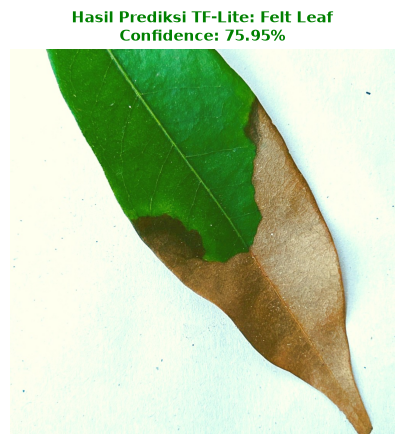

Hasil Klasifikasi: Felt Leaf (Tingkat Keyakinan: 75.95%)


In [ ]:
# Menjalankan pengujian inferensi pada sampel citra dari test set
sample_folders = [os.path.join(test_dir, c) for c in os.listdir(test_dir) if os.path.isdir(os.path.join(test_dir, c))]
if sample_folders:
    sample_images = [os.path.join(sample_folders[0], f) for f in os.listdir(sample_folders[0]) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    if sample_images:
        test_img_path = sample_images[0]
        print("Pengujian inferensi TF-Lite pada citra:", test_img_path)
        pred_label, conf = predict_image_tflite(test_img_path, interpreter, class_names, img_size=IMG_SIZE)
        print(f"Hasil Klasifikasi: {pred_label} (Tingkat Keyakinan: {conf:.2f}%)")